# EDA – Breast Cancer Wisconsin (Diagnostic)
Fase CRISP-DM **Data Understanding** (Laporan Subbab 2.1.4 dan 3.2.2). Notebook ini memakai fungsi yang sama dengan
`train.py` (modul `preprocessing/eda.py`), sehingga angka di notebook = angka di aplikasi dan laporan.

EDA menjawab lima pertanyaan:
1. Adakah missing value, duplikat, atau outlier?
2. Apakah kelas target tidak seimbang?
3. Bagaimana distribusi setiap atribut? (univariat)
4. Atribut mana yang memiliki daya pemisah terhadap target? (bivariat)
5. Bagaimana hubungan antarvariabel? (multivariat)

Bagian terakhir menunjukkan **keputusan preprocessing yang diambil dari temuan EDA**.

In [1]:
%matplotlib inline
import pandas as pd
from IPython.display import display
from preprocessing import data as prep
from preprocessing import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)
df = prep.muat_dataset()
hasil = eda.jalankan_eda(df)
print(df.shape)
df.head()

(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,2,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,3,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,4,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,5,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


## 1. Kualitas data (missing value, duplikat, tipe data)

In [2]:
pd.Series(hasil["kualitas"])

jumlah_data         569
jumlah_kolom         32
jumlah_fitur         30
fitur_numerik        30
missing_value         0
kolom_missing        {}
duplikat              0
id_duplikat           0
nilai_negatif         0
label_unik       [B, M]
dtype: object

## 2. Distribusi kelas dan imbalance

benign                          357
malignant                       212
persen_benign               62.7000
persen_malignant            37.3000
rasio_mayoritas_minoritas    1.6800
tidak_seimbang                 True
dtype: object

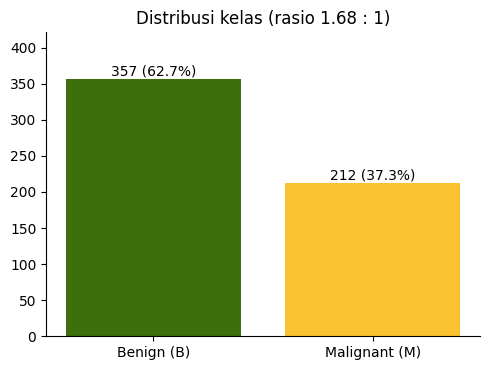

In [3]:
display(pd.Series(hasil["distribusi_kelas"]))
eda.plot_distribusi_kelas(df);

## 3. Univariat: statistik deskriptif dan perbedaan skala

In [4]:
stat = eda.statistik_deskriptif(df)
display(pd.Series(hasil["skala"]))
stat.sort_values("max", ascending=False)

fitur_nilai_terbesar              area_worst
nilai_maks_terbesar                4254.0000
fitur_nilai_terkecil    fractal_dimension_se
nilai_maks_terkecil                   0.0298
rasio_rentang                    140569.1000
perlu_penskalaan                        True
dtype: object

,min,max,mean,median,std,rentang
area_worst,185.2000,4254.0000,880.5831,686.5000,569.3570,4068.8000
area_mean,143.5000,2501.0000,654.8891,551.1000,351.9141,2357.5000
area_se,6.8020,542.2000,40.3371,24.5300,45.4910,535.3980
perimeter_worst,50.4100,251.2000,107.2612,97.6600,33.6025,200.7900
perimeter_mean,43.7900,188.5000,91.9690,86.2400,24.2990,144.7100
texture_worst,12.0200,49.5400,25.6772,25.4100,6.1463,37.5200
texture_mean,9.7100,39.2800,19.2896,18.8400,4.3010,29.5700
radius_worst,7.9300,36.0400,16.2692,14.9700,4.8332,28.1100
radius_mean,6.9810,28.1100,14.1273,13.3700,3.5240,21.1290
perimeter_se,0.7570,21.9800,2.8661,2.2870,2.0219,21.2230


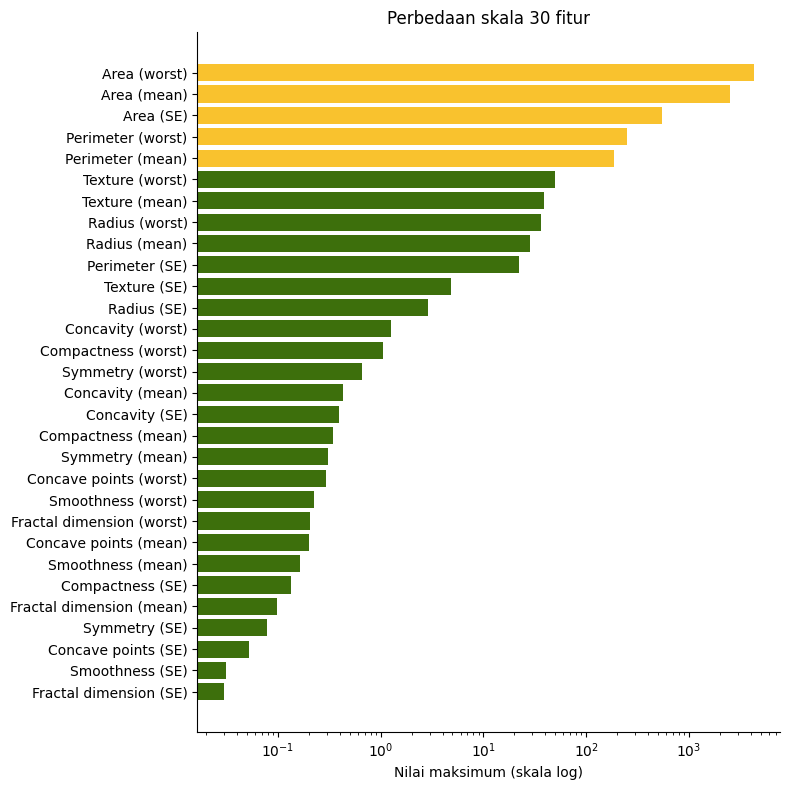

In [5]:
eda.plot_skala_fitur(stat);

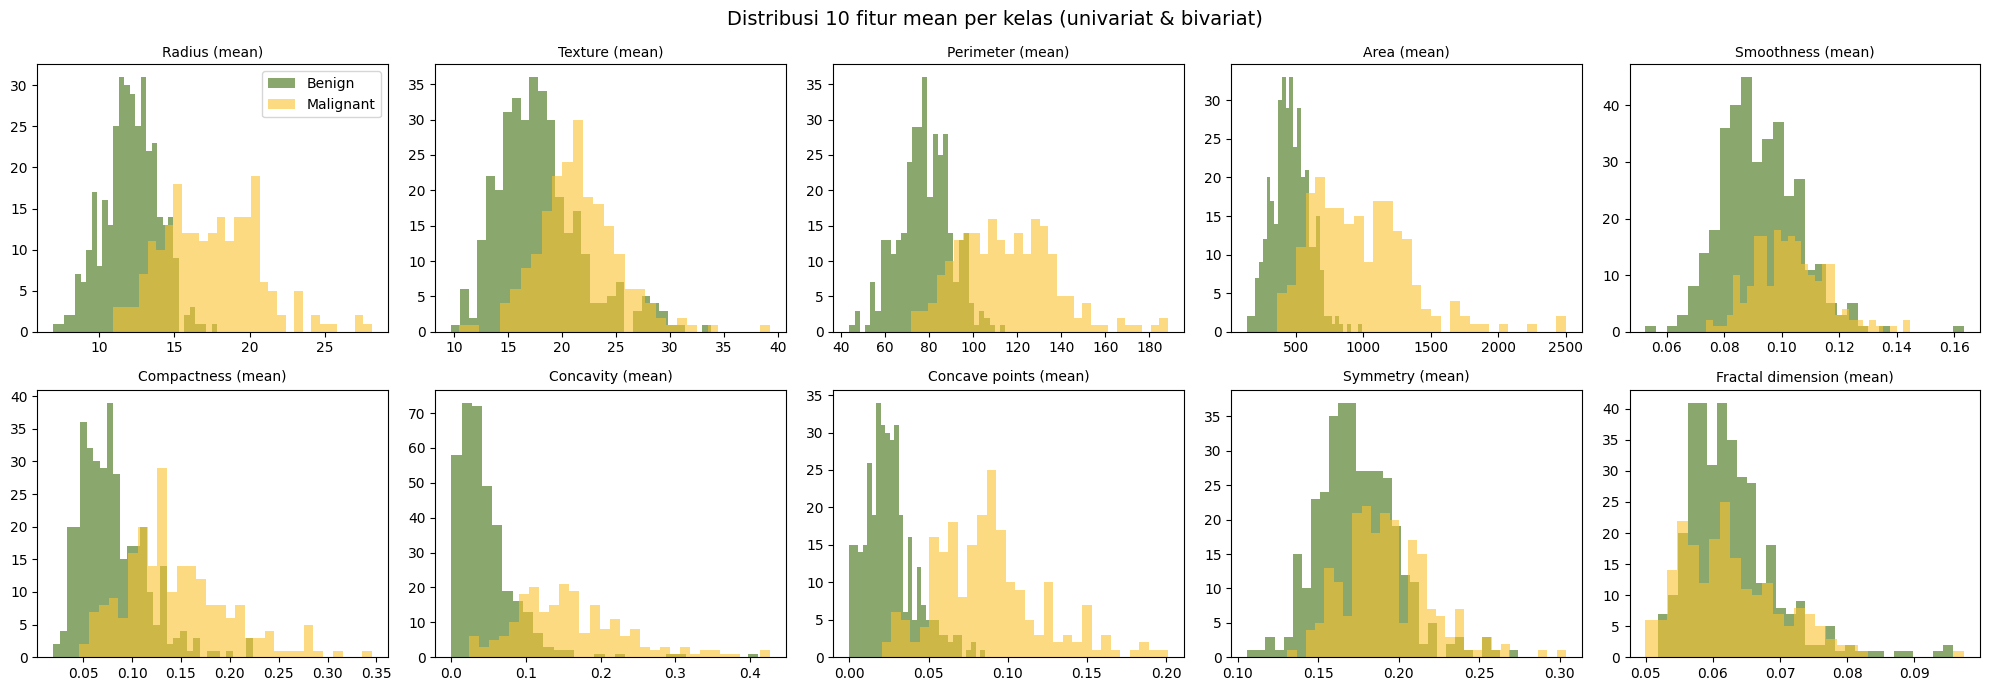

In [6]:
eda.plot_histogram(df);

## 4. Outlier (metode IQR)
Outlier jika nilai < Q1 − 1,5·IQR atau > Q3 + 1,5·IQR.

In [7]:
tabel_outlier, ringkas_outlier = eda.deteksi_outlier(df)
display(pd.Series(ringkas_outlier))
tabel_outlier.head(10)

total_nilai_outlier                     608.0000
total_nilai                           17070.0000
pasien_dengan_outlier                   171.0000
pasien_outlier_malignant                114.0000
pasien_outlier_benign                    57.0000
persen_malignant_punya_outlier           53.8000
persen_benign_punya_outlier              16.0000
persen_nilai_outlier_dari_malignant      77.1000
di_atas_batas_atas                      605.0000
di_bawah_batas_bawah                      3.0000
dtype: float64

,batas_bawah,batas_atas,jumlah_outlier,persen,dari_malignant,dari_benign
area_se,-23.1600,86.2000,65,11.4000,65,0
radius_se,-0.1374,0.8487,38,6.7000,37,1
perimeter_se,-1.0205,5.9835,38,6.7000,38,0
area_worst,-337.7500,1937.0500,35,6.2000,35,0
smoothness_se,0.0007,0.0126,30,5.3000,4,26
fractal_dimension_se,-0.0012,0.0080,28,4.9000,10,18
compactness_se,-0.0160,0.0615,28,4.9000,14,14
symmetry_se,0.0027,0.0360,27,4.7000,16,11
area_mean,-123.3000,1326.3000,25,4.4000,25,0
fractal_dimension_worst,0.0405,0.1230,24,4.2000,18,6


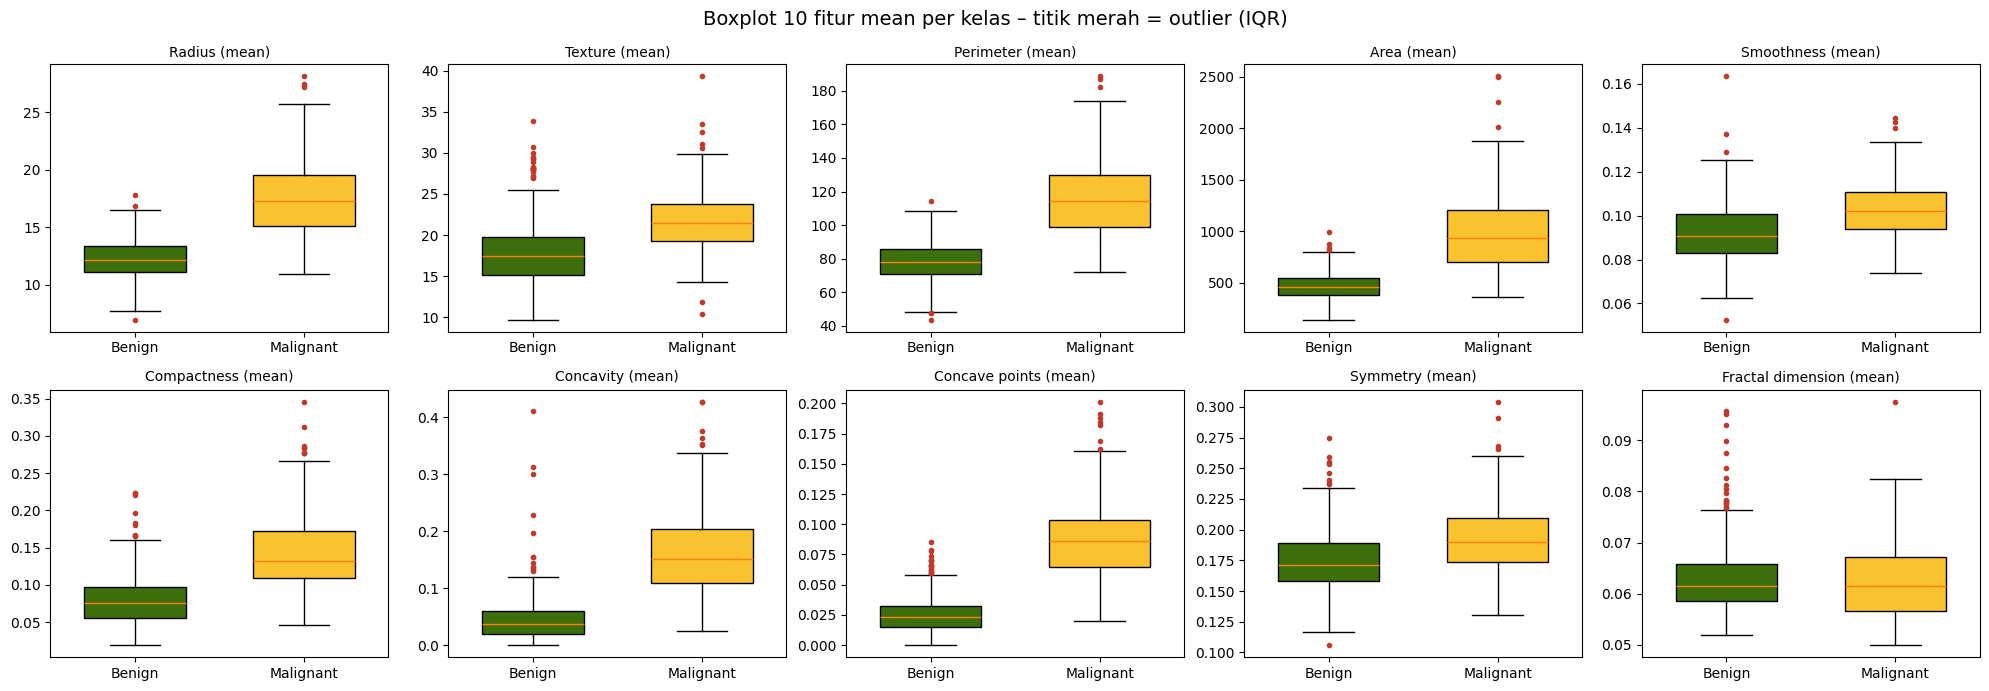

In [8]:
eda.plot_boxplot_outlier(df);

## 5. Bivariat: daya pemisah fitur terhadap diagnosis

,rata_B,rata_M,rasio_M_per_B
concavity_mean,0.0461,0.1608,3.4907
area_se,21.1351,72.6724,3.4385
concave_points_mean,0.0257,0.0880,3.4214
concavity_worst,0.1662,0.4506,2.7106
area_worst,558.8994,1422.2863,2.5448
concave_points_worst,0.0744,0.1822,2.4480
perimeter_se,2.0003,4.3239,2.1616
radius_se,0.2841,0.6091,2.1440
area_mean,462.7902,978.3764,2.1141
compactness_worst,0.1827,0.3748,2.0519


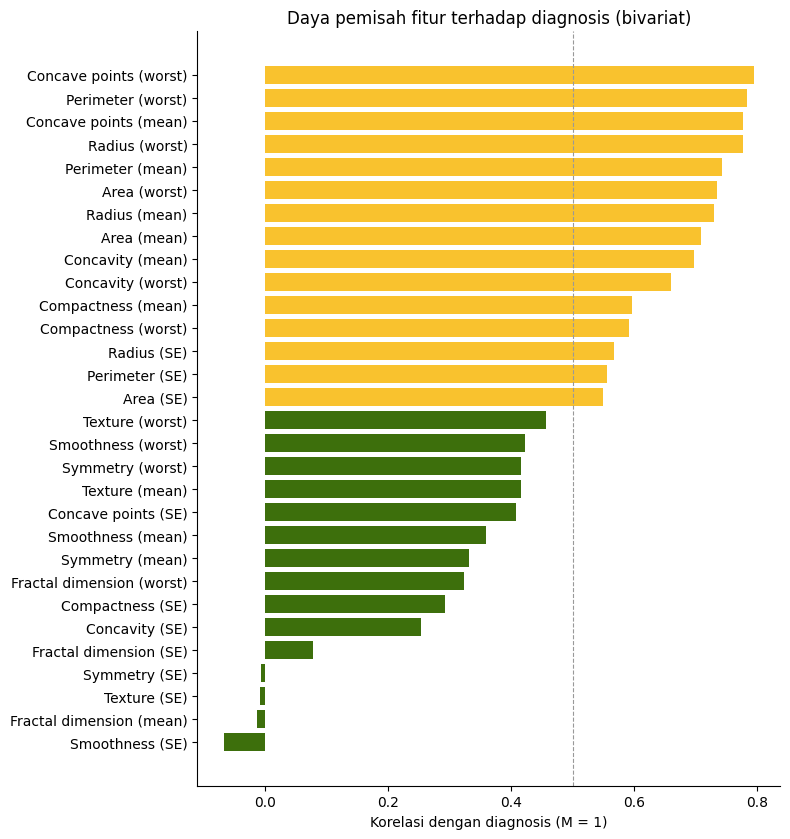

In [9]:
eda.plot_korelasi_target(df);
eda.rasio_rata_kelas(df).head(10)

## 6. Multivariat: korelasi antarfitur

,fitur_1,fitur_2,korelasi
0,radius_mean,perimeter_mean,0.9979
1,radius_worst,perimeter_worst,0.9937
2,radius_mean,area_mean,0.9874
3,perimeter_mean,area_mean,0.9865
4,radius_worst,area_worst,0.9840
5,perimeter_worst,area_worst,0.9776
6,radius_se,perimeter_se,0.9728
7,perimeter_mean,perimeter_worst,0.9704
8,radius_mean,radius_worst,0.9695
9,perimeter_mean,radius_worst,0.9695


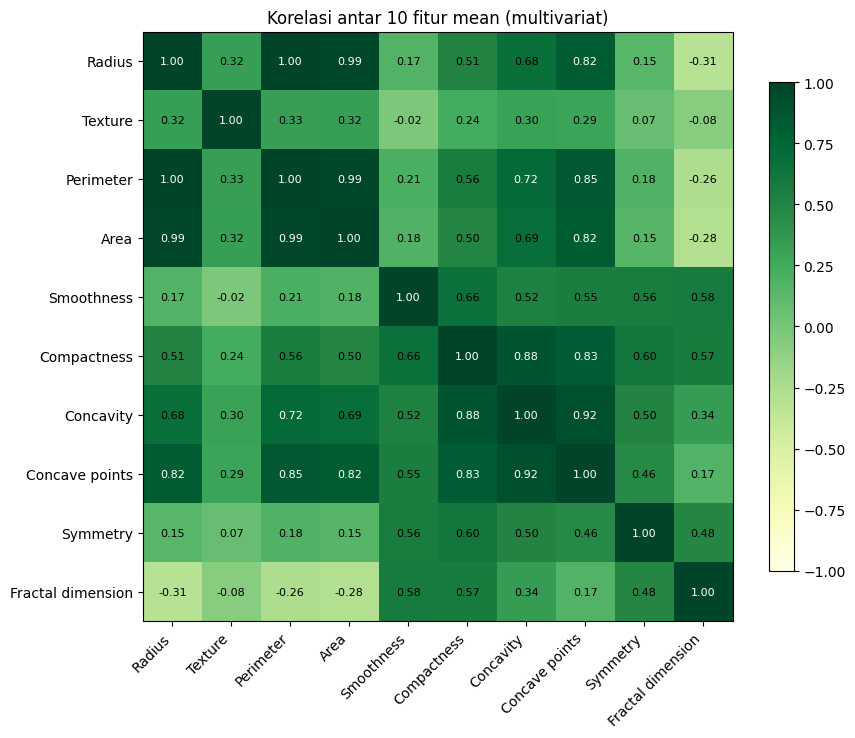

In [10]:
eda.plot_heatmap(df);
eda.pasangan_korelasi_tinggi(df)

## 7. Keputusan preprocessing berdasarkan temuan EDA

In [11]:
rencana = pd.DataFrame(prep.rencana_preprocessing(hasil))
rencana.index = range(1, len(rencana) + 1)
with pd.option_context("display.max_colwidth", None):
    display(rencana)

,langkah,temuan,tindakan,alasan
1,Penanganan duplikat,0 baris duplikat,Tidak ada yang dihapus,Data ganda membuat model belajar dari pola yang sama dua kali dan dapat bocor ke data uji.
2,Penanganan missing value,0 nilai kosong,Tidak perlu imputasi,Model tidak dapat memproses nilai kosong; median dipilih karena tahan terhadap outlier.
3,Penanganan outlier,171 pasien memiliki outlier (IQR); 77.1% nilai outlier berasal dari malignant,Outlier dipertahankan (tidak dihapus),"Nilai ekstrem didominasi kelas malignant, yaitu ciri inti sel ganas yang lebih besar dan tidak beraturan; menghapusnya membuang informasi diagnostik. Pengaruh skala ditangani z-score."
4,Penghapusan kolom ID,Kolom id hanya nomor identitas pasien,Hapus kolom id,Tidak menyimpan informasi diagnostik sehingga tidak boleh dipelajari model.
5,Transformasi label,"Label berupa huruf B, M","Malignant = 1, Benign = 0",Model membutuhkan label numerik; malignant ditetapkan sebagai kelas positif.
6,Seleksi fitur,"21 pasangan fitur berkorelasi > 0.9 (misalnya radius, perimeter, area)",Seluruh 30 fitur tetap digunakan,"Random Forest memilih fitur secara acak di setiap node, SVM RBF memakai semua fitur dalam perhitungan jarak, dan SHAP perlu menilai kontribusi setiap fitur (Rumusan Masalah 2)."
7,Pembagian data,"Kelas tidak seimbang: 62.7% benign, 37.3% malignant (rasio 1.68 : 1)",Hold-out 80 : 20 secara stratified,Menjaga proporsi kelas tetap sama pada data latih dan data uji.
8,Standardisasi fitur,"Skala berbeda jauh: area_worst sampai 4254.0, fractal_dimension_se maksimum 0.0298",z-score dengan mu dan sigma dari data latih,Kernel RBF berbasis jarak sehingga fitur berskala besar akan mendominasi (Subbab 2.1.8.1).


In [12]:
siap = prep.siapkan_data(df, hasil)
for baris in siap["log"]:
    print("-", baris)

- Duplikat: tidak ada, tidak ada baris yang dihapus
- Outlier: 171 pasien memiliki outlier, dipertahankan
- Kolom id dihapus; label diubah: Malignant = 1, Benign = 0
- Seleksi fitur: tidak dilakukan, 30 fitur digunakan
- Split stratified: 455 latih (37.4% malignant), 114 uji (36.8% malignant)
- Missing value: tidak ada, tidak perlu imputasi
- Standardisasi z-score: mu dan sigma dihitung dari data latih
